# Risk model v1: data exploration and sanity checks

The training data is **synthetic**: 300 projects simulated week by week by `data_generator/simulate.py`, with real Open-Meteo rainfall. Every assumption is in `data_generator/ASSUMPTIONS.md`. This notebook checks that the simulated projects look plausible and that each feature relates to the outcomes the way the assumptions say it should, before any model is trained.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (7, 3.2), 'axes.spines.top': False, 'axes.spines.right': False})
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
df = pd.read_csv(ROOT / 'data' / 'snapshots.csv')
projects = df.groupby('project_id').first()
projects['delay_share'] = projects.delay_days / projects.planned_duration_days * 100
print(f'{len(df):,} weekly snapshots, {len(projects)} projects')
projects[['planned_duration_days', 'contract_value_m', 'delay_days', 'delay_share', 'overrun_pct', 'final_score']].describe().round(1)

18,153 weekly snapshots, 300 projects


,planned_duration_days,contract_value_m,delay_days,delay_share,overrun_pct,final_score
count,300.0,300.0,300.0,300.0,300.0,300.0
mean,390.2,586.1,43.9,11.1,7.8,51.2
std,76.6,526.7,38.5,9.2,6.5,28.9
min,217.0,60.0,-32.0,-8.0,-3.7,0.0
25%,336.0,271.2,15.8,4.2,3.0,28.0
50%,381.5,430.6,37.2,10.2,6.5,49.0
75%,434.0,731.6,69.8,17.1,11.1,74.0
max,665.0,3611.5,196.8,50.2,32.8,100.0


## Outcomes

Delays and overruns should be common but not universal, with a long tail of badly late jobs.

final_score
Low       0.400000
Medium    0.313333
High      0.286667
Name: count, dtype: float64

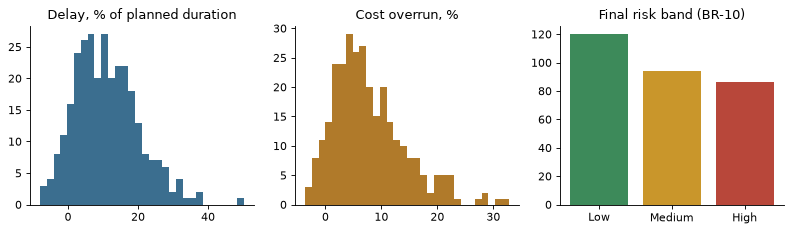

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].hist(projects.delay_share, bins=30, color='#3b6e8f'); axes[0].set_title('Delay, % of planned duration')
axes[1].hist(projects.overrun_pct, bins=30, color='#b07a2a'); axes[1].set_title('Cost overrun, %')
bands = pd.cut(projects.final_score, [-1, 39, 69, 100], labels=['Low', 'Medium', 'High']).value_counts().reindex(['Low', 'Medium', 'High'])
axes[2].bar(bands.index, bands.values, color=['#3d8a5a', '#c9962b', '#b8473a']); axes[2].set_title('Final risk band (BR-10)')
plt.tight_layout()
bands / len(projects)

## Sanity checks

1. **The hidden management quality drives outcomes**, and its symptoms (missed reports, late deliveries, crew shortfalls) are visible in the features. The model never sees `quality` itself.

In [3]:
mid = df[(df.elapsed_pct > 40) & (df.elapsed_pct < 60)].groupby('project_id').mean(numeric_only=True)
checks = mid[['quality', 'missing_reports_14', 'late_deliveries_count', 'avg_lateness_days', 'crew_vs_plan_pct', 'progress_gap_pct', 'budget_variance_pct']].corr()['quality'].round(2)
print('Correlation with hidden quality at mid-project:'); print(checks.drop('quality'))
assert checks['missing_reports_14'] < 0 and checks['progress_gap_pct'] > 0

Correlation with hidden quality at mid-project:
missing_reports_14      -0.69
late_deliveries_count   -0.12
avg_lateness_days       -0.44
crew_vs_plan_pct         0.35
progress_gap_pct         0.32
budget_variance_pct     -0.43
Name: quality, dtype: float64


2. **Wetter towns lose more time.** Programmes allow for only half of a town's usual rain (`RAIN_ALLOWANCE`, an assumption: see ASSUMPTIONS.md), and the pace is calibrated so the median project is 10% late, so wet-zone towns should come out later than the dry zone.

In [4]:
by_town = projects.groupby('town').agg(projects=('delay_share', 'size'), median_delay_share=('delay_share', 'median')).round(1)
by_town.sort_values('median_delay_share')

,projects,median_delay_share
town,,
jaffna,52,5.5
kurunegala,42,7.1
kandy,44,7.2
batticaloa,32,7.4
colombo,40,10.6
galle,42,14.3
ratnapura,48,18.1


3. **Falling behind early predicts finishing late.** The progress gap at mid-project against the final delay:

correlation -0.8


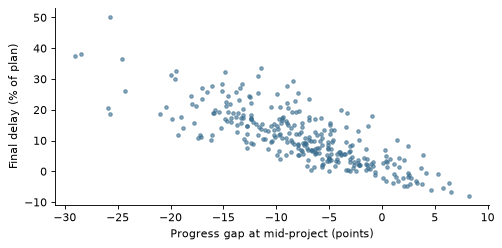

In [5]:
joined = mid.join(projects[['delay_share']], rsuffix='_final')
plt.scatter(joined.progress_gap_pct, joined.delay_share, s=10, alpha=0.6, color='#3b6e8f')
plt.xlabel('Progress gap at mid-project (points)'); plt.ylabel('Final delay (% of plan)')
print('correlation', round(joined.progress_gap_pct.corr(joined.delay_share), 2))

4. **Features against outcomes at mid-project** (Pearson correlation). Signs should match the assumptions: behind plan, late deliveries, missed reports and short crews mean more delay; cost running over its budgeted value means more overrun.

In [6]:
features = ['progress_gap_pct', 'progress_rate_trend', 'late_deliveries_count', 'avg_lateness_days', 'rain_days_next_14', 'wet_days_ahead', 'budget_variance_pct', 'crew_vs_plan_pct', 'missing_reports_14']
targets = mid[features].join(projects[['delay_days', 'overrun_pct']])
targets.corr().loc[features, ['delay_days', 'overrun_pct']].round(2)

,delay_days,overrun_pct
progress_gap_pct,-0.75,-0.35
progress_rate_trend,-0.54,-0.33
late_deliveries_count,0.27,0.13
avg_lateness_days,0.19,0.03
rain_days_next_14,0.25,0.03
wet_days_ahead,0.45,0.10
budget_variance_pct,0.23,0.49
crew_vs_plan_pct,-0.41,-0.18
missing_reports_14,0.24,0.09


## Leakage

Weeks of the same project are strongly related, so a random row split would put weeks of one project in both training and test data and flatter the model. `train.py` splits **by project** (80/20) and tunes with cross-validation grouped by project.

## Evaluation (from `train.py`, held-out projects)

In [7]:
metrics = json.loads((ROOT / 'models' / 'risk-v1.2.0' / 'metrics.json').read_text())
rows = []
for target, m in metrics['targets'].items():
    rows.append({'target': target, 'model': 'LightGBM', **m['test']})
    rows.append({'target': target, 'model': 'linear baseline', **m['baseline_test']})
pd.DataFrame(rows).set_index(['target', 'model'])

mae   rmse     r2
target      model                               
delay_days  LightGBM         19.13  25.49  0.645
            linear baseline  22.55  29.09  0.538
overrun_pct LightGBM          4.80   6.23  0.224
            linear baseline   4.72   6.06  0.266

In [8]:
rc = metrics['risk_class']
print(f"F1 for the High class: {rc['f1_high']} (baseline {rc['f1_high_baseline']}); macro F1 {rc['f1_macro']}")
cm = pd.DataFrame(rc['confusion_matrix']['rows_true_cols_predicted'], index=['true low', 'true medium', 'true high'], columns=['pred low', 'pred medium', 'pred high'])
cm

F1 for the High class: 0.565 (baseline 0.589); macro F1 0.579


,pred low,pred medium,pred high
true low,767,375,4
true medium,145,619,106
true high,108,812,668


In [9]:
bt = metrics['backtest']
print(f"Backtest: {bt['flagged']} of {bt['high_projects']} projects that ended High were flagged High,")
print(f"at a median of {bt['median_flagged_at_elapsed_pct']}% of the planned duration ({bt['median_weeks_before_planned_end']} weeks before the planned end).")
print(f"{bt['low_projects_ever_flagged_high']} of {bt['low_projects']} projects that ended Low were ever flagged High.")
pd.Series(metrics['delay_mae_by_elapsed'], name='delay MAE (days) by stage')

Backtest: 22 of 23 projects that ended High were flagged High,
at a median of 52.2% of the planned duration (30.0 weeks before the planned end).
1 of 22 projects that ended Low were ever flagged High.


0-25%      26.8
25-50%     21.9
50-75%     16.7
75-100%    13.4
late       15.4
Name: delay MAE (days) by stage, dtype: float64

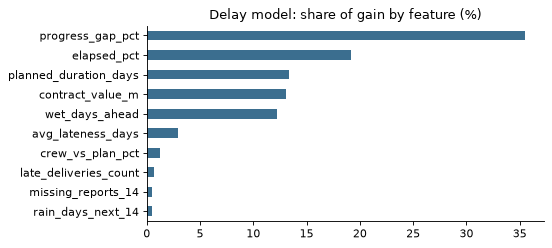

In [10]:
gain = pd.Series(metrics['targets']['delay_days']['importance_gain_pct']).head(10)[::-1]
gain.plot.barh(color='#3b6e8f', title='Delay model: share of gain by feature (%)'); plt.tight_layout()

## Conclusions

- The simulated projects behave as the assumptions intend; no feature has a backwards relationship.
- The delay model clearly beats the linear baseline, and the season still ahead (`wet_days_ahead`) is among its main inputs. The overrun model is weak, and in this run the linear baseline is slightly better: most overrun comes from overheads and variations the app does not record yet.
- These are results on simulated data. They show the pipeline works; they do not prove the model is right about real projects. Validating the assumptions with a contractor comes first.